<a href="https://colab.research.google.com/github/eduzegarra/grade_01/blob/main/water_spillover_coding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os
os.chdir('/content/drive/MyDrive/__ANDREA/')
!ls

abstract_Ica_paper_v03.docx
agroex
enaho_ica_dataset_report.pdf
enaho_ica_finest_georef_cluster_year_with_climate_aug_mar_2008_2024.csv
enaho_ica_finest_georef_cluster_year_with_climate_aug_mar_2008_2024.dta
gdf_ica.gpkg
ica_districts.gpkg


In [3]:
## Import ENAHO data with water access
import pandas as pd
df = pd.read_stata('enaho_ica_finest_georef_cluster_year_with_climate_aug_mar_2008_2024.dta')

In [4]:
### Import panel of firms with their cumulative water rights
import geopandas as gpd
df_rights=gpd.read_file('/content/drive/MyDrive/__ANDREA/agroex/panel_water_rights.gpkg')

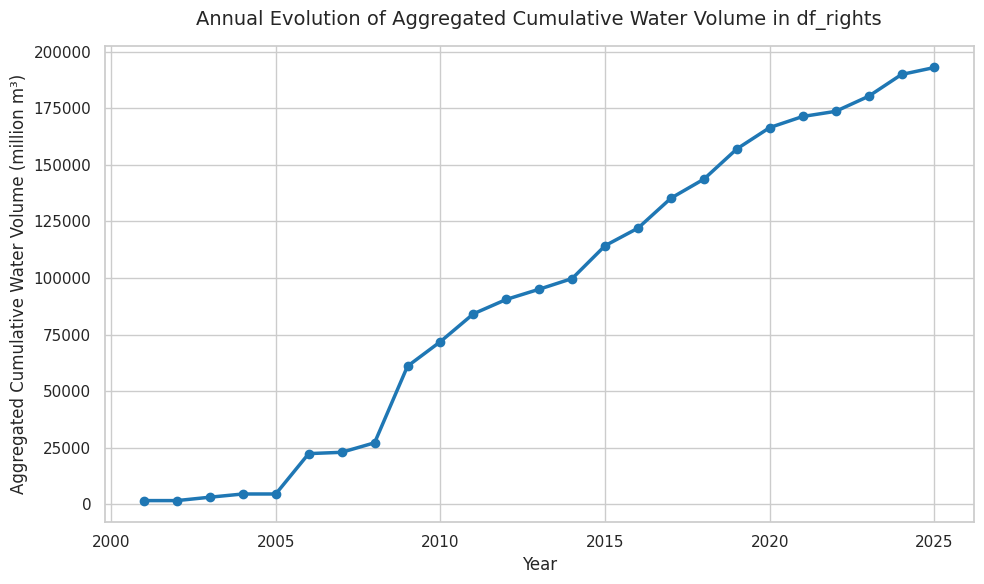

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group by year and calculate the sum of cumulative water volume
rights_annual = df_rights.groupby('year')['cum_vol_mil'].sum().reset_index()

# Configure the plot
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Plot the line chart
plt.plot(rights_annual['year'], rights_annual['cum_vol_mil'], color='tab:blue', marker='o', linewidth=2.5)

# Labels and titles
plt.title("Annual Evolution of Aggregated Cumulative Water Volume in df_rights", fontsize=14, pad=15)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Aggregated Cumulative Water Volume (million m³)", fontsize=12)

plt.tight_layout()
plt.show()

In [6]:
## keep Ica province
df_ica=df.loc[df.province_name=='Ica']

In [7]:
## drop observations with NaN for 'water_days_per_week_mean'
df_ica=df_ica.dropna(subset='water_days_per_week_mean')

In [8]:
# Create a yearly panel dataframe grouped by the coordinates and year
panel_df = df_ica.groupby(['climate_longitude', 'climate_latitude', 'year'], as_index=False).agg(district=('district_name','first'),
    water_days_mean=('water_days_per_week_mean', 'mean'), water_hours_mean=('water_hours_per_day_mean', 'mean'),
    ccpp_name=('ccpp_name', 'first'),
    ccpp_code=('ccpp_code', 'first'),
)

# Display the panel's basic info and preview the first few rows
print(f"Panel shape: {panel_df.shape}")
display(panel_df.head(10))

Panel shape: (917, 8)


,climate_longitude,climate_latitude,year,district,water_days_mean,water_hours_mean,ccpp_name,ccpp_code
0,-75.923664,-13.929205,2021,Salas,7.000000,1.333333,BARRIO SANTA CRUZ DE VILLACURI (VILLACURI),43.0
1,-75.923664,-13.929205,2024,Salas,7.000000,2.000000,BARRIO SANTA CRUZ DE VILLACURI (VILLACUR,43.0
2,-75.923660,-13.929205,2023,Salas,6.333333,1.333333,SANTA CRUZ DE VILLACURI (VILLACURI),43.0
3,-75.923660,-13.929205,2022,Salas,7.000000,1.666667,SANTA CRUZ DE VILLACURI (VILLACURI),43.0
4,-75.921693,-13.930172,2017,Salas,7.000000,3.000000,AAHH SANTA CRUZ DE VILLACURI (VILLACURI),43.0
5,-75.921693,-13.930172,2018,Salas,7.000000,2.166667,BARRIO SANTA CRUZ DE VILLACURI (VILLACURI),43.0
6,-75.921690,-13.930646,2019,Salas,7.000000,2.000000,CENTRO POBLADO MENOR SANTA CRUZ DE VILLACURI (...,43.0
7,-75.921646,-13.930193,2020,Salas,7.000000,2.600000,CENTRO POBLADO MENOR SANTA CRUZ DE VILLA,43.0
8,-75.921646,-13.930193,2021,Salas,7.000000,2.000000,CENTRO POBLADO MENOR SANTA CRUZ DE VILLA,43.0
9,-75.921646,-13.930193,2022,Salas,7.000000,2.500000,CENTRO POBLADO MENOR SANTA CRUZ DE VILLA,43.0


In [9]:
import geopandas as gpd
import pandas as pd

# 1. Convert panel_df to a GeoDataFrame using its WGS84 coordinates
gdf_panel = gpd.GeoDataFrame(
    panel_df,
    geometry=gpd.points_from_xy(panel_df['climate_longitude'], panel_df['climate_latitude']),
    crs="EPSG:4326"
)

# Force projection to UTM 18S (EPSG:32718) to measure distance in meters accurately
target_crs = "EPSG:32718"
gdf_panel_projected = gdf_panel.to_crs(target_crs)
df_rights_projected = df_rights.to_crs(target_crs)

print(f"Projected both datasets to: {target_crs}")

# Create a 1500m buffer around each community point to define the circular area
gdf_panel_projected['buffered_geom'] = gdf_panel_projected.geometry.buffer(750)

# 2. Perform yearly buffer spatial aggregation
joined_list = []

# Get shared years between both panel datasets
shared_years = set(gdf_panel_projected['year'].unique()).intersection(set(df_rights_projected['year'].unique()))
print(f"Matching datasets over shared years: {sorted(list(shared_years))}")

for yr in sorted(list(shared_years)):
    # Subset for the specific year
    gdf_panel_yr = gdf_panel_projected[gdf_panel_projected['year'] == yr].copy()
    df_rights_yr = df_rights_projected[df_rights_projected['year'] == yr].copy()

    if not gdf_panel_yr.empty and not df_rights_yr.empty:
        # Set geometry to the 500m buffer for the join
        gdf_panel_yr_buffered = gdf_panel_yr.set_geometry('buffered_geom')

        # Spatial join: find all rights that fall within the 700m buffer
        joined_yr = gpd.sjoin(
            gdf_panel_yr_buffered,
            df_rights_yr.rename(columns={'year': 'year_rights'}),
            how='left',
            predicate='intersects'
        )

        # Aggregate the joined rights per panel point (group by coordinate-year key) to sum 'cum_vol_mil'
        # Keep other primary columns using 'first'
        agg_yr = joined_yr.groupby(['climate_longitude', 'climate_latitude', 'year'], as_index=False).agg({
            'district': 'first',
            'water_days_mean': 'first',
            'water_hours_mean': 'first',
            'ccpp_name': 'first',
            'ccpp_code': 'first',
            'geometry': 'first', # restores the original point geometry
            'cum_vol_mil': lambda x: x.sum(skipna=True) # Sum cumulative volume in the 750m buffer
        })

        joined_list.append(agg_yr)

# 3. Concatenate all yearly slices into a single panel GeoDataFrame
if joined_list:
    panel_linked = gpd.GeoDataFrame(pd.concat(joined_list, ignore_index=True), crs=target_crs)
    print(f"\nSuccessfully created panel GeoDataFrame with shape: {panel_linked.shape}")
    display(panel_linked.head())
else:
    print("No overlapping years found to perform the spatial join.")

Projected both datasets to: EPSG:32718
Matching datasets over shared years: [np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024)]

Successfully created panel GeoDataFrame with shape: (917, 10)


,climate_longitude,climate_latitude,year,district,water_days_mean,water_hours_mean,ccpp_name,ccpp_code,geometry,cum_vol_mil
0,-75.921693,-13.930172,2017,Salas,7.000000,3.000000,AAHH SANTA CRUZ DE VILLACURI (VILLACURI),43.0,POINT (400431.89 8459803.484),1256.256
1,-75.776100,-14.003263,2017,Salas,3.000000,1.000000,CIUDAD DE CERRO PRIETO,71.0,POINT (416187.313 8451775.478),280.915
2,-75.775149,-13.974333,2017,Salas,4.166667,1.833333,PUBLO JOVEN NUESTRA SERORA DE GUADALUPE,1.0,POINT (416279.485 8454975.536),0.000
3,-75.774689,-14.000270,2017,Salas,3.200000,1.400000,CACERIO DE CERRO PRIETO,71.0,POINT (416338.583 8452107.025),280.915
4,-75.774606,-13.990929,2017,Salas,7.000000,2.333333,CIUDAD DE GUADALUPE,1.0,POINT (416344.138 8453140.142),0.000


In [10]:
districts=gpd.read_file('ica_districts.gpkg')

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

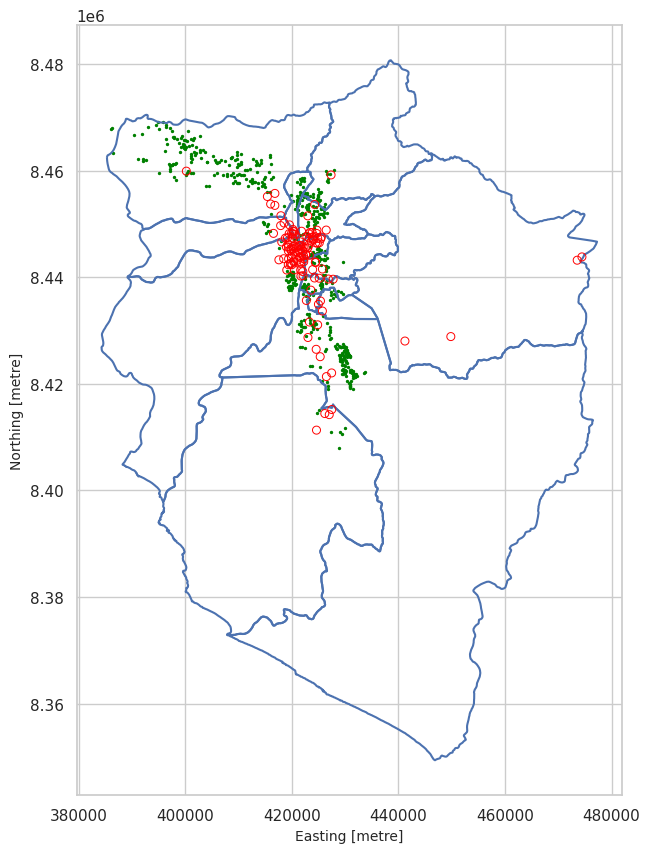

In [11]:
axis=districts.boundary.plot(figsize=(10,10))
gdf_panel_yr_buffered.boundary.plot(ax=axis, color='red', linewidth=0.7)
df_rights_yr.plot(ax=axis, markersize=2, color='green')

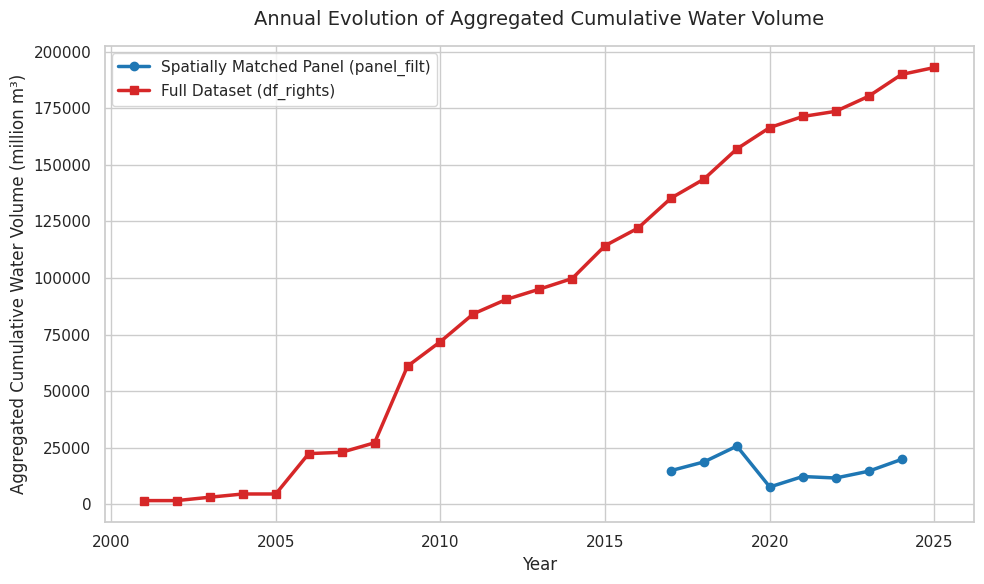

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group by year and calculate the sum of cumulative water volume
rights_annual = panel_linked.groupby('year')['cum_vol_mil'].sum().reset_index()
rights_annual2 = df_rights.groupby('year')['cum_vol_mil'].sum().reset_index()

# Configure the plot
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Plot the line chart
# Blue line: Sum of matched cumulative volume in panel_filt (2017-2024)
plt.plot(rights_annual['year'], rights_annual['cum_vol_mil'], color='tab:blue', marker='o', linewidth=2.5, label='Spatially Matched Panel (panel_filt)')
# Red line: Sum of total cumulative volume in df_rights (2001-2025)
plt.plot(rights_annual2['year'], rights_annual2['cum_vol_mil'], color='tab:red', marker='s', linewidth=2.5, label='Full Dataset (df_rights)')

# Labels and titles
plt.title("Annual Evolution of Aggregated Cumulative Water Volume", fontsize=14, pad=15)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Aggregated Cumulative Water Volume (million m³)", fontsize=12)
plt.legend(loc='upper left')

plt.tight_layout()
plt.show()

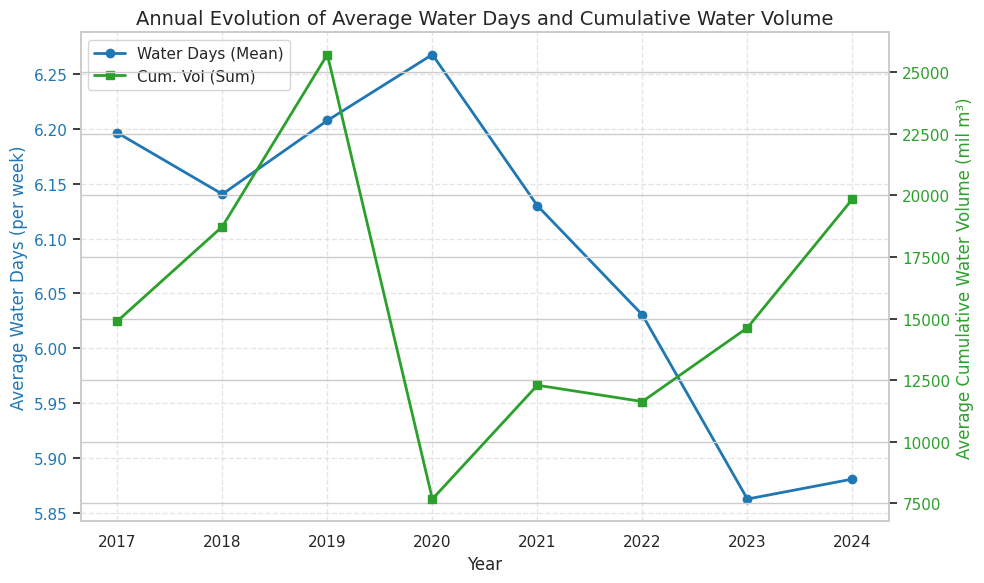

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the annual averages from panel_linked
annual_trends = panel_linked.groupby('year').agg({'water_days_mean':'mean', 'cum_vol_mil':'sum'}).reset_index()

# Configure the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot water_days_mean on the left y-axis
color = 'tab:blue'
ax1.set_xlabel('Year', fontsize=12)
ax1.set_ylabel('Average Water Days (per week)', color=color, fontsize=12)
line1 = ax1.plot(annual_trends['year'], annual_trends['water_days_mean'], color=color, marker='o', linewidth=2, label='Water Days (Mean)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

# Create a second y-axis that shares the same x-axis
ax2 = ax1.twinx()
color = 'tab:green'
ax2.set_ylabel('Average Cumulative Water Volume (mil m³)', color=color, fontsize=12)
line2 = ax2.plot(annual_trends['year'], annual_trends['cum_vol_mil'], color=color, marker='s', linewidth=2, label='Cum. Vol (Sum)')
ax2.tick_params(axis='y', labelcolor=color)

# Combine legends
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.title('Annual Evolution of Average Water Days and Cumulative Water Volume', fontsize=14)
plt.tight_layout()
plt.show()

In [14]:
annual_trends

,year,water_days_mean,cum_vol_mil
0,2017,6.196496,14899.149919
1,2018,6.140552,18737.175919
2,2019,6.207738,25717.713459
3,2020,6.267876,7676.760805
4,2021,6.130049,12295.989619
5,2022,6.030450,11633.073849
6,2023,5.862495,14627.878849
7,2024,5.880667,19848.275489


In [15]:
import numpy as np
from shapely.geometry import box
import geopandas as gpd

# Get total bounds of the unique points in meters
minx, miny, maxx, maxy = panel_linked.total_bounds

# Define the grid spacing (500 meters)
grid_size = 1000.0

# Generate grid coordinates
x_coords = np.arange(minx, maxx + grid_size, grid_size)
y_coords = np.arange(miny, maxy + grid_size, grid_size)

# Create grid cell geometries
grid_cells = []
for x in x_coords[:-1]:
    for y in y_coords[:-1]:
        grid_cells.append(box(x, y, x + grid_size, y + grid_size))

# Create a GeoDataFrame for the grid
gdf_grid = gpd.GeoDataFrame(geometry=grid_cells, crs=panel_linked.crs)

# Drop any conflicting index columns from panel_linked before performing sjoin
panel_linked_clean = panel_linked.drop(columns=['index_right'], errors='ignore')

# Keep only grid cells that intersect at least one point in panel_linked
gdf_grid_filtered = gpd.sjoin(gdf_grid, panel_linked_clean, how="inner", predicate="intersects")
gdf_grid = gdf_grid.loc[gdf_grid.index.isin(gdf_grid_filtered.index)].copy()
gdf_grid = gdf_grid.reset_index(drop=True)

print(f"Created a grid with {len(gdf_grid)} cells (500m x 500m) containing the points.")
gdf_grid.head()

Created a grid with 138 cells (500m x 500m) containing the points.


,geometry
0,"POLYGON ((401218.5 8458841.261, 401218.5 84598..."
1,"POLYGON ((401218.5 8459841.261, 401218.5 84608..."
2,"POLYGON ((401218.5 8463841.261, 401218.5 84648..."
3,"POLYGON ((413218.5 8443841.261, 413218.5 84448..."
4,"POLYGON ((414218.5 8442841.261, 414218.5 84438..."


In [16]:
# Perform spatial join to align points with grid cells after dropping conflicting index column
panel_linked_clean = panel_linked.drop(columns=['index_right'], errors='ignore')
joined = gpd.sjoin(gdf_grid, panel_linked_clean, how="left", predicate="intersects")

# Count the number of points in each grid cell
counts = joined.groupby(joined.index).size()

# Handle cells that might have 0 points if any exist (though they were filtered)
gdf_grid['point_count'] = joined.groupby(joined.index)['index_right'].count()

print(gdf_grid['point_count'].describe())
gdf_grid.head()

count    138.000000
mean       6.644928
std        7.781506
min        1.000000
25%        2.000000
50%        4.000000
75%        7.000000
max       37.000000
Name: point_count, dtype: float64


,geometry,point_count
0,"POLYGON ((401218.5 8458841.261, 401218.5 84598...",7
1,"POLYGON ((401218.5 8459841.261, 401218.5 84608...",4
2,"POLYGON ((401218.5 8463841.261, 401218.5 84648...",1
3,"POLYGON ((413218.5 8443841.261, 413218.5 84448...",1
4,"POLYGON ((414218.5 8442841.261, 414218.5 84438...",1


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

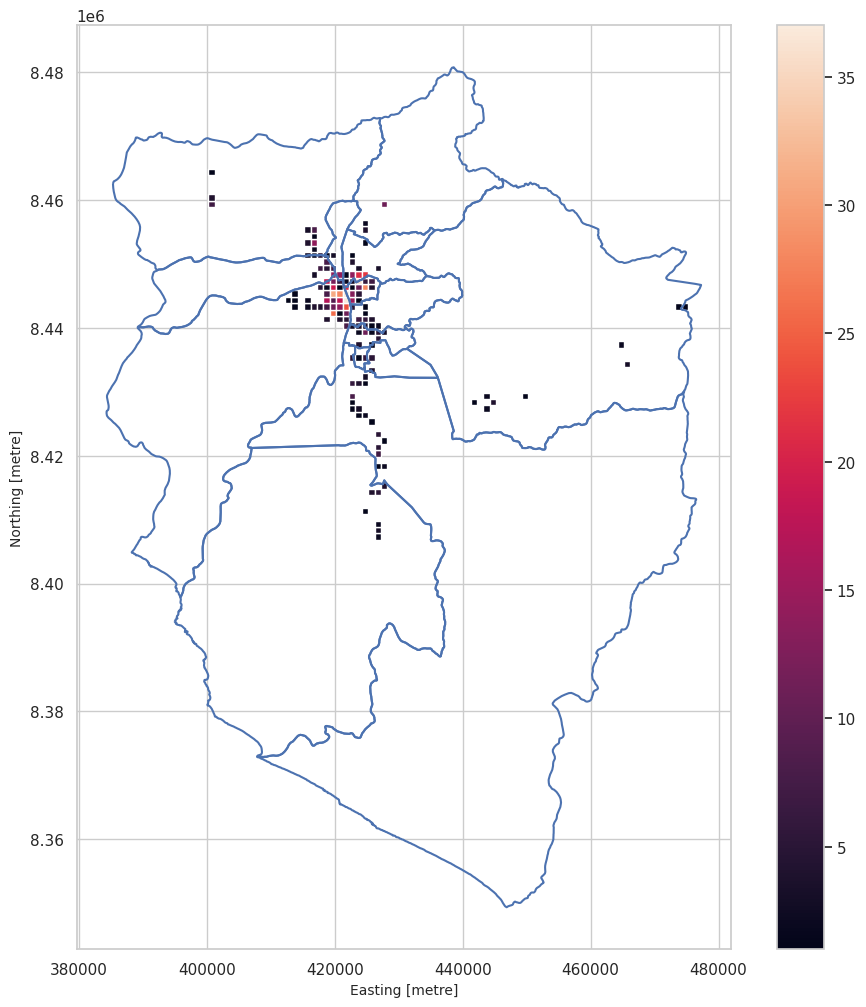

In [17]:

axis=districts.boundary.plot(figsize=(12,12))
gdf_grid.plot(ax=axis, column='point_count', legend=True, figsize=(10,10))

In [18]:
# Reset the index of joined to turn the grid cell index into an actual column named 'index'
joined_reset = joined.reset_index()

# Group by the grid cell index (now 'index' column) and year to aggregate
grid_yearly_panel = joined_reset.groupby(['index', 'year'], as_index=False).agg(
    mean_water_days=('water_days_mean', 'mean'),
    mean_water_hours=('water_hours_mean', 'mean'),
    cum_vol_mil=('cum_vol_mil','sum'),
    observation_count=('water_days_mean', 'count')
)

# Rename the 'index' column to 'grid_cell_id' for clarity
grid_yearly_panel = grid_yearly_panel.rename(columns={'index': 'grid_cell_id'})

# Display basic information and a preview of the new yearly panel
print(f"Yearly grid panel shape: {grid_yearly_panel.shape}")
display(grid_yearly_panel.head(15))

Yearly grid panel shape: (542, 6)


,grid_cell_id,year,mean_water_days,mean_water_hours,cum_vol_mil,observation_count
0,0,2017,7.000000,3.000000,1256.256,1
1,0,2018,7.000000,2.166667,1256.256,1
2,0,2019,7.000000,2.000000,1256.256,1
3,0,2020,7.000000,2.600000,1256.256,1
4,0,2021,7.000000,2.000000,1256.256,1
5,0,2022,7.000000,2.500000,1256.256,1
6,0,2023,7.000000,1.333333,1256.256,1
7,1,2021,7.000000,1.333333,841.536,1
8,1,2022,7.000000,1.666667,841.536,1
9,1,2023,6.333333,1.333333,841.536,1


In [19]:
## Estimate regressions
import numpy as np
import pandas as pd
import statsmodels.api as sm
from linearmodels.panel import PanelOLS, PooledOLS

# 1. Prepare data, filter out zeros, apply log transformation, and set the multi-index
reg_grid_log = grid_yearly_panel.dropna(subset=['mean_water_days', 'cum_vol_mil']).copy()

# Exclude observations where cum_vol_mil is 0 to avoid -inf values from log transformation
reg_grid_log = reg_grid_log[reg_grid_log['cum_vol_mil'] > 0].copy()
reg_grid_log['log_cum_vol_mil'] = np.log(reg_grid_log['cum_vol_mil'])

# Convert year to datetime for proper panel time-indexing and set index
reg_grid_log['year'] = pd.to_datetime(reg_grid_log['year'], format='%Y')
reg_grid_log = reg_grid_log.set_index(['grid_cell_id', 'year'])

# Add constant for regression
exog_log = sm.add_constant(reg_grid_log['log_cum_vol_mil'])
endog_log = reg_grid_log['mean_water_days']

# 2. Estimate the Pooled OLS Model with Logged Independent Variable
pooled_log_model = PooledOLS(endog_log, exog_log)
pooled_log_res = pooled_log_model.fit()
print("=== POOLED OLS REGRESSION WITH LOG(VOLUME) ===")
print(pooled_log_res)

# 3. Estimate the Panel Fixed Effects Model with Logged Independent Variable
fe_log_model = PanelOLS(endog_log, exog_log, entity_effects=True, time_effects=True)
fe_log_res = fe_log_model.fit()
print("\n=== PANEL FIXED EFFECTS REGRESSION WITH LOG(VOLUME) (Entity & Time FE) ===")
print(fe_log_res)

=== POOLED OLS REGRESSION WITH LOG(VOLUME) ===
                          PooledOLS Estimation Summary                          
Dep. Variable:        mean_water_days   R-squared:                        0.0677
Estimator:                  PooledOLS   R-squared (Between):              0.0054
No. Observations:                 174   R-squared (Within):               0.0081
Date:                Mon, Nov 02 2026   R-squared (Overall):              0.0677
Time:                        17:58:05   Log-likelihood                   -333.14
Cov. Estimator:            Unadjusted                                           
                                        F-statistic:                      12.497
Entities:                          56   P-value                           0.0005
Avg Obs:                       3.1071   Distribution:                   F(1,172)
Min Obs:                       1.0000                                           
Max Obs:                       8.0000   F-statistic (robust): 

In [20]:
from linearmodels.panel import RandomEffects

# Estimate the Panel Random Effects Model with Logged Independent Variable
re_log_model = RandomEffects(endog_log, exog_log)
re_log_res = re_log_model.fit()

print("=== PANEL RANDOM EFFECTS REGRESSION WITH LOG(VOLUME) ===")
print(re_log_res)

=== PANEL RANDOM EFFECTS REGRESSION WITH LOG(VOLUME) ===
                        RandomEffects Estimation Summary                        
Dep. Variable:        mean_water_days   R-squared:                        0.0674
Estimator:              RandomEffects   R-squared (Between):              0.0644
No. Observations:                 174   R-squared (Within):               0.0086
Date:                Mon, Nov 02 2026   R-squared (Overall):              0.0102
Time:                        17:58:06   Log-likelihood                   -125.28
Cov. Estimator:            Unadjusted                                           
                                        F-statistic:                      4.8035
Entities:                          56   P-value                           0.0297
Avg Obs:                       3.1071   Distribution:                   F(1,172)
Min Obs:                       1.0000                                           
Max Obs:                       8.0000   F-statistic 

In [21]:
import numpy as np
import scipy.stats as stats

# Extract coefficients and covariance matrices, excluding the constant term
b_fe = fe_log_res.params.drop('const')
b_re = re_log_res.params.drop('const')

cov_fe = fe_log_res.cov.drop(index='const', columns='const')
cov_re = re_log_res.cov.drop(index='const', columns='const')

# Calculate the Hausman test statistic: (b_fe - b_re)' * pinv(cov_fe - cov_re) * (b_fe - b_re)
diff = b_fe - b_re
cov_diff = cov_fe - cov_re

# Use pseudo-inverse in case of near-singularity
chi2_stat = np.dot(np.dot(diff.T, np.linalg.pinv(cov_diff)), diff)
df_hausman = diff.shape[0]
p_value = 1 - stats.chi2.cdf(chi2_stat, df_hausman)

print("=== HAUSMAN TEST ===")
print(f"Chi-Squared Statistic: {chi2_stat:.4f}")
print(f"Degrees of Freedom   : {df_hausman}")
print(f"p-value              : {p_value:.4f}")

if p_value < 0.05:
    print("\nResult: Reject the null hypothesis (p < 0.05).")
    print("Interpretation: The Random Effects estimators are inconsistent. Use the Fixed Effects model.")
else:
    print("\nResult: Fail to reject the null hypothesis (p >= 0.05).")
    print("Interpretation: The Random Effects estimators are consistent and efficient. You may use the Random Effects model.")

=== HAUSMAN TEST ===
Chi-Squared Statistic: 0.2339
Degrees of Freedom   : 1
p-value              : 0.6286

Result: Fail to reject the null hypothesis (p >= 0.05).
Interpretation: The Random Effects estimators are consistent and efficient. You may use the Random Effects model.


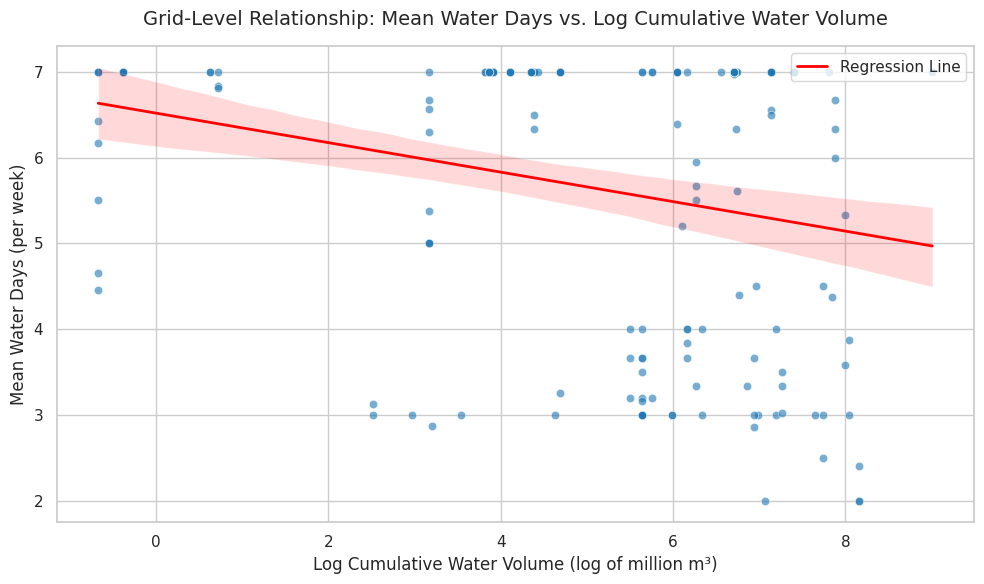

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the style for the plot
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Reset the index of reg_grid_log to easily access the variables as columns
plot_data = reg_grid_log.reset_index()

# Create a scatter plot with a linear regression line
sns.regplot(
    data=plot_data,
    x="log_cum_vol_mil",
    y="mean_water_days",
    scatter_kws={'alpha': 0.6, 'edgecolor': 'w', 'linewidths': 0.5, 'color': 'tab:blue'},
    line_kws={'color': 'red', 'linewidth': 2, 'label': 'Regression Line'}
)

# Add title, axis labels, and legend
plt.title("Grid-Level Relationship: Mean Water Days vs. Log Cumulative Water Volume", fontsize=14, pad=15)
plt.xlabel("Log Cumulative Water Volume (log of million m³)", fontsize=12)
plt.ylabel("Mean Water Days (per week)", fontsize=12)
plt.legend(loc='upper right')

# Adjust layout and display
plt.tight_layout()
plt.show()

In [23]:
# Retrieve coefficients, standard errors, and p-values from the fitted models
models_results = {
    'Pooled OLS': pooled_log_res,
    'Panel FE (Entity & Time)': fe_log_res,
    'Random Effects': re_log_res
}

print("=== COMPARISON OF ESTIMATED COEFFICIENTS FOR 'log_cum_vol_mil' ===\n")
print(f"{'Model':<30} | {'Coefficient':<12} | {'Std. Error':<10} | {'P-value':<8} | {'Impact of 10% Increase':<25}")
print("-" * 96)

for name, res in models_results.items():
    coef = res.params['log_cum_vol_mil']
    std_err = res.std_errors['log_cum_vol_mil']
    p_val = res.pvalues['log_cum_vol_mil']

    # In a log-linear model: y = alpha + beta * log(x)
    # A 10% increase in x (e.g., water volume) leads to an absolute change in y of approximately: beta * ln(1.10) days
    # Or roughly (beta / 100) per 1% change in volume.
    impact_10pct = coef * 0.09531  # ln(1.10) is approx 0.09531

    print(f"{name:<30} | {coef:<12.4f} | {std_err:<10.4f} | {p_val:<8.4f} | {impact_10pct:+.4f} water days/week")

print("\n=== INTERPRETATION ===")
print("Since the independent variable is log-transformed (log_cum_vol_mil) and the dependent variable is in levels (mean_water_days):")
print("- A 10% increase in aggregated cumulative water volume is associated with the printed change in water days per week.")
print("- A doubling (100% increase) of water volume is associated with a change of approximately [beta * ln(2)] days per week.")


=== COMPARISON OF ESTIMATED COEFFICIENTS FOR 'log_cum_vol_mil' ===

Model                          | Coefficient  | Std. Error | P-value  | Impact of 10% Increase   
------------------------------------------------------------------------------------------------
Pooled OLS                     | -0.1720      | 0.0487     | 0.0005   | -0.0164 water days/week
Panel FE (Entity & Time)       | -0.1166      | 0.1197     | 0.3323   | -0.0111 water days/week
Random Effects                 | -0.1621      | 0.0740     | 0.0297   | -0.0155 water days/week

=== INTERPRETATION ===
Since the independent variable is log-transformed (log_cum_vol_mil) and the dependent variable is in levels (mean_water_days):
- A 10% increase in aggregated cumulative water volume is associated with the printed change in water days per week.
- A doubling (100% increase) of water volume is associated with a change of approximately [beta * ln(2)] days per week.
